### US Dollar Index (DX-Y.NYB)

In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')

#### DX-Yの時系列データを取得

In [4]:
dxy = 'DX-Y'
market = 'NYB'

response = request_api.update_stock_timeseries_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [5]:
dxy_timeseries_df = request_api.get_stock_time_series_data(
    code=dxy,
    market=market,
    start=start,
    end=end
)
dxy_timeseries_df

取得件数: 7054


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1089885,DX-Y,NYB,1998-11-17,94.970001,95.160004,94.519997,94.949997,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1089886,DX-Y,NYB,1998-11-18,95.279999,95.309998,94.730003,94.940002,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1089887,DX-Y,NYB,1998-11-19,95.540001,95.570000,94.870003,95.360001,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1089888,DX-Y,NYB,1998-11-20,95.809998,95.860001,95.360001,95.519997,0,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1089889,DX-Y,NYB,1998-11-23,96.320000,96.620003,95.769997,95.870003,0,95.328000,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7049,1187717,DX-Y,NYB,2026-10-05,102.169998,102.540001,101.860001,101.919998,0,101.602000,...,99.174593,8.025271,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7050,1187718,DX-Y,NYB,2026-10-06,101.830002,102.290001,101.750000,102.139999,0,101.792000,...,99.206891,16.750619,True,NaN,NaN,NaN,NaN,NaN,NaN,False
7051,1187719,DX-Y,NYB,2026-10-07,102.239998,102.500000,101.889999,101.889999,0,101.887999,...,99.275607,26.278494,True,NaN,NaN,NaN,NaN,NaN,91.82906,False
7052,1187720,DX-Y,NYB,2026-10-08,102.139999,102.470001,102.029999,102.230003,0,102.039999,...,99.330177,35.055067,True,NaN,NaN,NaN,NaN,NaN,NaN,False


In [6]:
def stock_prices_and_index(
        code: str,
        name: str,
        start: str,
        end: str,
        market: str | None = None,
        df_sp: pd.DataFrame | None = None,
        index_name: str | None = None,
        df_index: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # INDEXを統合
    if df_index is not None:
        df_index_tmp = df_index.copy() if df_index is not None else pd.DataFrame()
        if "date" not in df_index_tmp.columns:
            df_index_tmp = df_index_tmp.reset_index()
        df_index_tmp["date"] = pd.to_datetime(df_index_tmp["date"])
        df_index_tmp = df_index_tmp.set_index("date")
        df_index_tmp = df_index_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA50_SP"] = df_sp_tmp["ma50"].reindex(df.index)
        df["MA200_SP"] = df_sp_tmp["ma200"].reindex(df.index)
    if df_index is not None:
        df["MA50_" + index_name] = df_index_tmp["ma50"].reindex(df.index)
        df["MA200_" + index_name] = df_index_tmp["ma200"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end,
        ma5=False,
        ma25=False,
        ma50=True,
        ma100=False,
        ma150=False,
        ma200=True,
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_SP"],
                name="SP_MA50",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_SP"],
                name="SP_MA200",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- INDEX（右軸） ---
    if df_index is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA50_" + index_name],
                name=index_name + "_MA50",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA200_" + index_name],
                name=index_name + "_MA200",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [7]:
name = "US Dollar Index"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_index(
    code=dxy,
    name=name,
    start=start,
    end=end,
    market=None,
    df_sp=None,
    df_index=None
)
fig.show()

取得件数: 653


In [8]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{dxy}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/DX-Y_2025-01-01_2026-10-10.png


#### 時系列データを保存

In [9]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{dxy}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = dxy_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.head()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,lower1,rci52,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,6860,1096745,DX-Y,NYB,98.419998,98.489998,98.150002,98.239998,0,98.094000,...,98.106292,-52.185606,False,NaN,NaN,NaN,NaN,NaN,NaN,True
2026-01-05,6861,1096746,DX-Y,NYB,98.269997,98.860001,98.250000,98.480003,0,98.206001,...,98.105077,-57.295313,False,NaN,NaN,-0.261667,NaN,NaN,NaN,False
2026-01-06,6862,1096747,DX-Y,NYB,98.580002,98.629997,98.160004,98.410004,0,98.278001,...,98.096908,-62.204388,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-07,6863,1096748,DX-Y,NYB,98.680000,98.750000,98.500000,98.580002,0,98.392001,...,98.099624,-65.495603,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-01-08,6864,1096749,DX-Y,NYB,98.930000,98.980003,98.680000,98.739998,0,98.490001,...,98.111452,-68.287373,False,NaN,NaN,NaN,NaN,NaN,NaN,False


{'fib_levels_down': {'1.000': np.float64(97.62999725341797),
  '1.272': np.float64(96.29447625732422),
  '1.382': np.float64(95.75437585449218),
  '1.618': np.float64(94.59561499023438)},
 'fib_levels_up': {'1.272': np.float64(103.87552191162109),
  '1.382': np.float64(104.41562231445313),
  '1.618': np.float64(105.57438317871093),
  '2.000': np.float64(107.45000457763672)},
 'swing_high': np.float64(102.54000091552734),
 'swing_low': np.float64(97.62999725341797),
 'df_with_fib':           date  index       id stock_code stock_market        open  \
 0   2026-01-02   6860  1096745       DX-Y          NYB   98.419998   
 1   2026-01-05   6861  1096746       DX-Y          NYB   98.269997   
 2   2026-01-06   6862  1096747       DX-Y          NYB   98.580002   
 3   2026-01-07   6863  1096748       DX-Y          NYB   98.680000   
 4   2026-01-08   6864  1096749       DX-Y          NYB   98.930000   
 ..         ...    ...      ...        ...          ...         ...   
 189 2026-10-05   

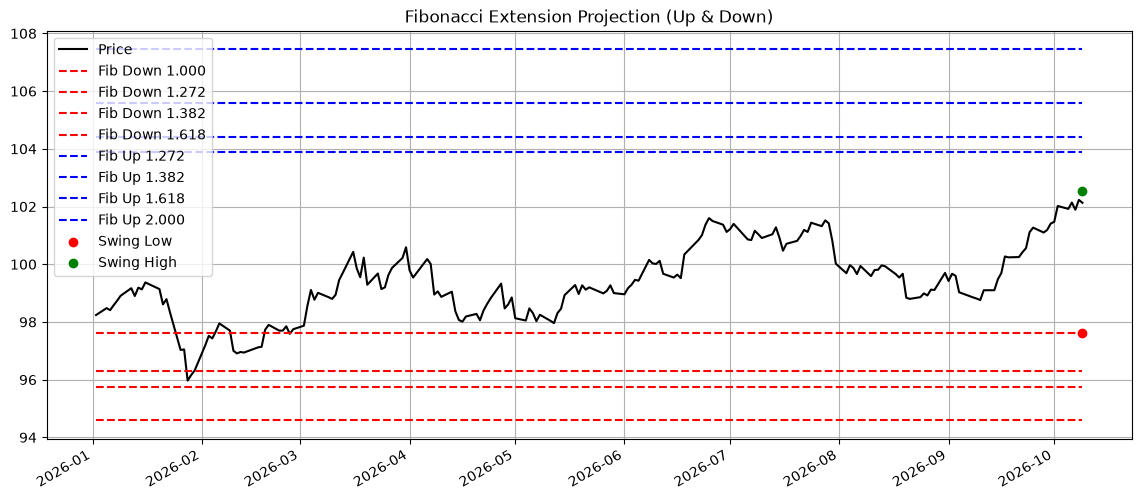

In [10]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [11]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{dxy}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")